1. Carga y exploración de los datos
cómo indica la consigna, filtro solo para una ciudad específica, en este caso, Boston.

In [4]:
import pandas as pd
import numpy as np

#ruta del archivo
archivo_restaurantes = 'C:/Users/Jere/Desktop/Henry/base_datos_restaurantes_USA_v2.csv'

df = pd.read_csv(archivo_restaurantes)

#antes de realizar la limpieza de datos hago esto para tener un pantallazo general de tamaño del dataset y de la cantidad de nulos
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.\n")
print("Valores nulos por columna:")
print(df.isnull().sum())
print(f"\nCantidad de filas completamente duplicadas: {df.duplicated().sum()}")

ciudad = 'Boston'
df = df[df['ciudad_residencia'] == ciudad].copy()
print(f"Dataset segmentado con éxito para la ciudad de: {ciudad}")
print(f"Cantidad de registros encontrados: {df.shape[0]} filas.\n")

Dimensiones del dataset: 30000 filas y 17 columnas.

Valores nulos por columna:
id_persona                       0
nombre                           0
apellido                         0
edad                           101
genero                           0
ciudad_residencia                0
estrato_socioeconomico           0
frecuencia_visita                0
promedio_gasto_comida          145
ocio                             0
consume_licor                    0
preferencias_alimenticias     1403
membresia_premium                0
telefono_contacto            15166
correo_electronico           15072
tipo_de_pago_mas_usado           0
ingresos_mensuales               0
dtype: int64

Cantidad de filas completamente duplicadas: 0
Dataset segmentado con éxito para la ciudad de: Boston
Cantidad de registros encontrados: 2547 filas.



2. Limpieza de datos

In [5]:
#limpiza de datos
df['telefono_contacto'] = df['telefono_contacto'].fillna(0)

#convierto a entero el campo edad
df['edad'] = pd.to_numeric(df['edad'], errors='coerce').astype("Int64")

#hay campos que en la edad tienen + de 100 años o menos de 0, reemplazo ese campo con la media
media_edad = df[(df['edad'] > 0) & (df['edad'] <= 100)]['edad'].median()
df['edad'] = np.where((df['edad'] > 100) | (df['edad'] < 0) | (df['edad'].isnull()), media_edad, df['edad'])

#hay algunos campos que tienen negativo, lo convierto a positivo
df['frecuencia_visita'] = df['frecuencia_visita'].abs()

# Convierto a Nan los 0 para que no alteren el promedio, entonces una vez hecho eso, si esta columna tiene Nan,
# muestro el promedio pero agrupado por estrato social. Hago eso para tener un valor representativo y que por ejemplo, si
# esa columna tiene NAn, y quiero rellenarla, no me lo promedia con alguien de otro estrato social
df['promedio_gasto_comida'] = df['promedio_gasto_comida'].replace(0, np.nan)
df['promedio_gasto_comida'] = df['promedio_gasto_comida'].fillna(
    df.groupby('estrato_socioeconomico')['promedio_gasto_comida'].transform('mean').round(2)
)

# controlo que el formato de mail cargado sea válido
email_valido = r'^[\w\.-]+@[\w\.-]+\.\w+$'

es_valido = df['correo_electronico'].str.match(email_valido, na=False)

df['correo_electronico'] = df['correo_electronico'].where(es_valido, "-")

# elimino registros duplicados
df.drop_duplicates(inplace=True)

print("restaurantes:")
print(df.head(50))

restaurantes:
     id_persona     nombre   apellido  edad     genero ciudad_residencia  \
3    4013002847      James    Shannon  41.0  Masculino            Boston   
7    8373803828      Julie      Russo  66.0   Femenino            Boston   
9    5394273061       Sara       Ball  37.0   Femenino            Boston   
19   9336353877       Mary    Bentley  29.0   Femenino            Boston   
26   1232293617  Elizabeth    Griffin  51.0   Femenino            Boston   
27   9116770673      April    Hoffman  57.0   Femenino            Boston   
48   6065852975       Mary  Hernandez  18.0   Femenino            Boston   
51   7601008318     George     Murphy  33.0  Masculino            Boston   
52   4899320322       John   Anderson  50.0  Masculino            Boston   
72   2562700723     Alyssa    Salinas  80.0   Femenino            Boston   
82   5666123927   Jonathon     Nguyen  18.0  Masculino            Boston   
87   1233356095   Kimberly   Harrison  47.0   Femenino            Boston  

In [14]:
#tabla que muestra porcentajes por género
print("\n1. Distribución por Género:")
tabla_genero = df['genero'].value_counts().reset_index()
tabla_genero.columns = ['Género', 'Cantidad']
tabla_genero['Porcentaje (%)'] = (tabla_genero['Cantidad'] / df.shape[0]) * 100
print(tabla_genero.to_string(index=False))

#tabla que muestra porcentajes por estrato social
print("\n2. Estrato socioeconómico:")
tabla_estrato = df['estrato_socioeconomico'].value_counts().reset_index()
tabla_estrato.columns = ['Estrato', 'Cantidad']
tabla_estrato['Porcentaje (%)'] = (tabla_estrato['Cantidad'] / df.shape[0]) * 100
print(tabla_estrato.to_string(index=False))

tabla_perfil = df.groupby('estrato_socioeconomico').agg({
    'frecuencia_visita': 'mean',
    'promedio_gasto_comida': 'mean',
    'tipo_de_pago_mas_usado': lambda x: x.mode()[0] if not x.mode().empty else "Sin datos",
    'preferencias_alimenticias': lambda x: x.mode()[0] if not x.mode().empty else "Sin datos",
    'consume_licor': lambda x: x.mode()[0] if not x.mode().empty else "Sin datos"
}).reset_index()

#renombro las columnas
tabla_perfil.columns = [
    'Estrato Socioeconómico', 
    'Visitas (Promedio)', 
    'Gasto Comida (Promedio $)', 
    'Pago Más Usado (Moda)', 
    'Preferencia Alimentos (Moda)', 
    'Consume Licor (Moda)'
]

#ordeno jerárquicamente de Bajo a Muy Alto
orden_estratos = ['Bajo', 'Medio', 'Alto', 'Muy Alto']
tabla_perfil['Estrato Socioeconómico'] = pd.Categorical(tabla_perfil['Estrato Socioeconómico'], categories=orden_estratos, ordered=True)
tabla_perfil = tabla_perfil.sort_values('Estrato Socioeconómico')

print(tabla_perfil.to_string(index=False))

#Medio de pago más usado agrupado por estrato social

print("\n3. Distribución de Medios de Pago por Estrato Socioeconómico:")
ct_pago = pd.crosstab(
    df['estrato_socioeconomico'], 
    df['tipo_de_pago_mas_usado'], 
    margins=True, 
    margins_name="Total General"
).reindex(orden_estratos + ["Total General"], fill_value=0)

ct_pago_pct = pd.crosstab(
    df['estrato_socioeconomico'], 
    df['tipo_de_pago_mas_usado'], 
    normalize='index'
) * 100
ct_pago_pct = ct_pago_pct.reindex(orden_estratos, fill_value=0).round(1)

print("\n--- Frecuencias Absolutas (Cantidad de Clientes) ---")
print(ct_pago)
print("\n--- Frecuencias Relativas (% por Estrato) ---")
print(ct_pago_pct.map(lambda x: f"{x}%"))
print("-" * 70)


#Preferencias alimenticas agrupadas por estrato social
print("\n4. Distribución de Preferencias Alimenticias por Estrato Socioeconómico:")
ct_alimentos = pd.crosstab(
    df['estrato_socioeconomico'], 
    df['preferencias_alimenticias'], 
    margins=True, 
    margins_name="Total General"
).reindex(orden_estratos + ["Total General"], fill_value=0)

print("\n--- Frecuencias Absolutas ---")
print(ct_alimentos)
print("-" * 70)

print("\n5. Promedios por Estrato Socioeconómico:")
tabla_estrato = df.groupby('estrato_socioeconomico')[['promedio_gasto_comida', 'ingresos_mensuales']].mean().reset_index()
print(tabla_estrato)


1. Distribución por Género:
   Género  Cantidad  Porcentaje (%)
 Femenino      1309       51.393797
Masculino      1238       48.606203

2. Estrato socioeconómico:
 Estrato  Cantidad  Porcentaje (%)
    Alto       759       29.799764
   Medio       729       28.621908
Muy Alto       533       20.926580
    Bajo       526       20.651747
Estrato Socioeconómico  Visitas (Promedio)  Gasto Comida (Promedio $) Pago Más Usado (Moda) Preferencia Alimentos (Moda) Consume Licor (Moda)
                  Bajo            1.524715                   9.849297              Efectivo                  Vegetariano                   Sí
                 Medio            3.423868                  20.162236              Efectivo                  Vegetariano                   Sí
                  Alto            4.901186                  34.724440              Efectivo                  Vegetariano                   Sí
              Muy Alto            7.240150                  56.795366              Efectivo 


Promedios por Estrato Socioeconómico:
  estrato_socioeconomico  promedio_gasto_comida  ingresos_mensuales
0                   Alto              34.724440         6230.945982
1                   Bajo               9.849297         1212.783270
2                  Medio              20.162236         2508.806584
3               Muy Alto              56.795366        13536.583490


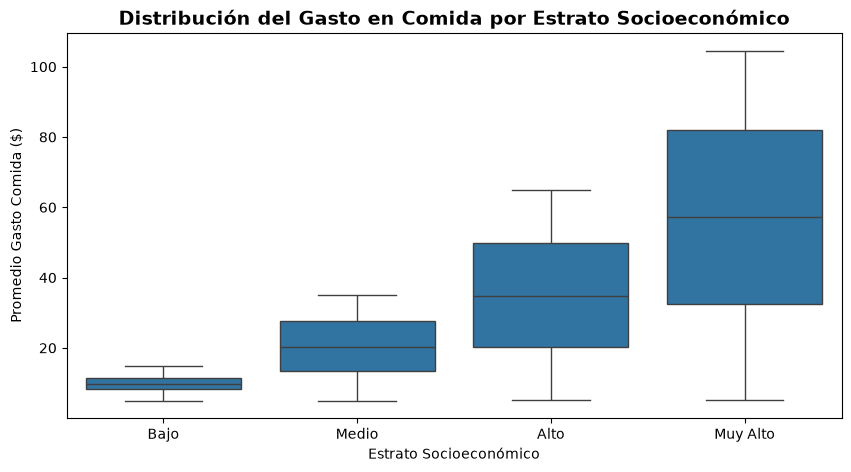

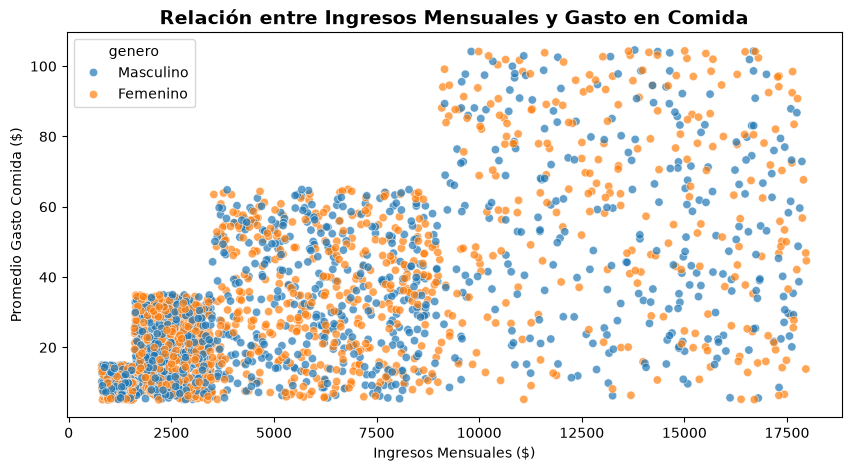


=== GENERANDO GRÁFICO DE PREFERENCIAS ALIMENTICIAS POR ESTRATO (BOSTON) ===


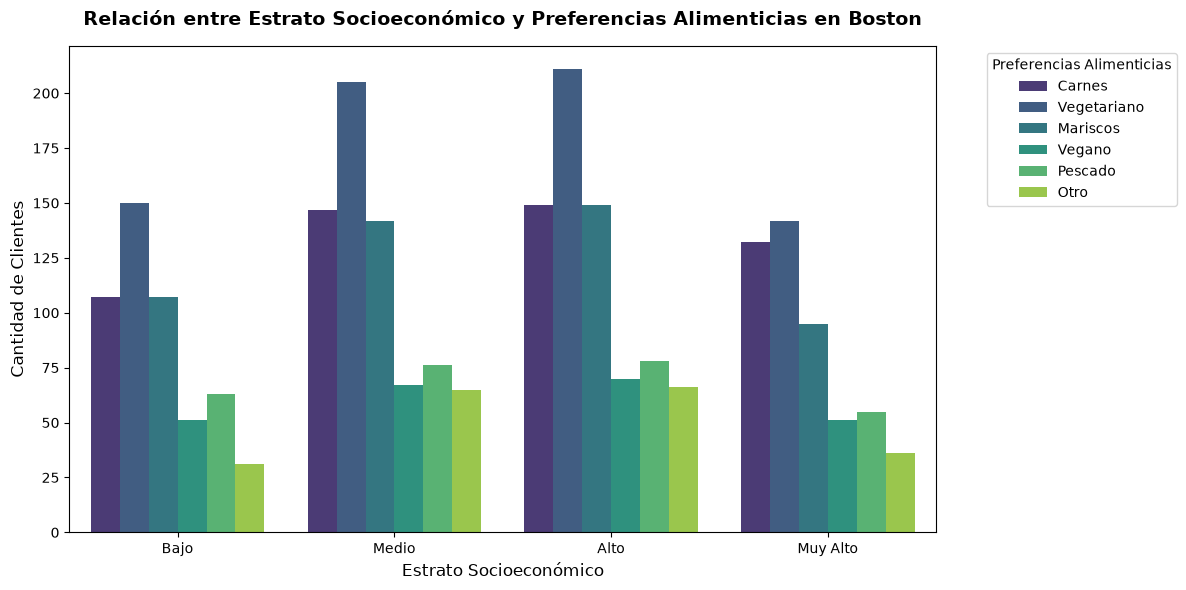

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import requests


# Gráfico 1: Distribución del Gasto Promedio en Comida según el Estrato
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='estrato_socioeconomico', y='promedio_gasto_comida',
            order=['Bajo', 'Medio', 'Alto', 'Muy Alto'])
plt.title('Distribución del Gasto en Comida por Estrato Socioeconómico', fontsize=14, fontweight='bold')
plt.xlabel('Estrato Socioeconómico')
plt.ylabel('Promedio Gasto Comida ($)')
plt.show()

# Gráfico 2: Relación entre Ingresos Mensuales y Gasto en Comida
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='ingresos_mensuales', y='promedio_gasto_comida', hue='genero', alpha=0.7)
plt.title('Relación entre Ingresos Mensuales y Gasto en Comida', fontsize=14, fontweight='bold')
plt.xlabel('Ingresos Mensuales ($)')
plt.ylabel('Promedio Gasto Comida ($)')
plt.show()

print("\n=== GENERANDO GRÁFICO DE PREFERENCIAS ALIMENTICIAS POR ESTRATO (BOSTON) ===")

# 1. Definimos el orden lógico de los estratos para el eje X
orden_estratos = ['Bajo', 'Medio', 'Alto', 'Muy Alto']

# 2. Creamos la figura y el gráfico de barras cruzado
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df, 
    x='estrato_socioeconomico', 
    hue='preferencias_alimenticias', 
    order=orden_estratos,
    palette='viridis'
)

# 3. Personalización del gráfico (Títulos, etiquetas y leyenda)
plt.title('Relación entre Estrato Socioeconómico y Preferencias Alimenticias en Boston', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Estrato Socioeconómico', fontsize=12)
plt.ylabel('Cantidad de Clientes', fontsize=12)

# Colocamos la leyenda a un costado para que no tape las barras
plt.legend(title='Preferencias Alimenticias', bbox_to_anchor=(1.05, 1), loc='upper left')

# Ajuste automático del diseño para que no se corten las etiquetas
plt.tight_layout()
plt.show()

Formulación de Respuestas y Recomendaciones Basadas en Hallazgos

📊 1. Conclusiones del Análisis de Patrones

• Alineación Estratégica de Preferencias: El análisis gráfico demostró que nuestra base de clientes en Boston está fuertemente orientada hacia opciones vegetarianas. Al contrastarlo con las tendencias externas extraídas de Yelp, se valida que los comercios locales de alta calificación ofrecen categorías alineadas con este comportamiento, permitiendo diseñar campañas sin fricción de interés.
• Comportamiento de Gasto por Rango de Precios: Los diagramas de caja (boxplots) revelan que los clientes de estratos Alto y Muy Alto registran variaciones significativas de gasto cuando se encuentran en zonas con indicadores de precio de Yelp de nivel $$ y $$$. Esto demuestra una alta elasticidad y disposición al gasto en entornos de alta reputación.

🎯 2. Recomendaciones de Marketing para la Toma de Decisiones

1. Campañas de Co-Branding y Alianzas: Utilizar el listado filtrado de los comercios con calificaciones mayores a 4.5 en Yelp para generar cupones de descuento cruzados o beneficios en nuestra app/negocio. Por ejemplo: "Por compras mayores a $X, obtené un beneficio en [Nombre del restaurante Top de Yelp]".
2. Segmentación de Notificaciones Push Geolocalizadas: Dirigir las pautas de marketing digital priorizando los estratos Alto y Muy Alto hacia zonas de Boston que concentren comercios gastronómicos con rangos de precio medio-alto en Yelp, maximizando el retorno de inversión publicitaria (ROI) al impactar al público con mayor capacidad de compra activa.